# Assignment 1 -- Linear Regression

**Student Name : Monika Oberoi   
Student Enroll Number : 2026paml539**

**Assignment : A supermarket chain wants to predict the sales revenue of its stores based on factors such as advertising budget, store size, number of employees, product categories, customer footfall, and promotional offers.**

You are provided with a retail sales dataset. Perform Exploratory Data Analysis (EDA), preprocessing, and build a Linear Regression model to predict store sales.

**Dataset Used : Dataset.csv**

# 1.  Exploratory Data Analysis (EDA) – [3 Marks]

Perform Exploratory Data Analysis on the dataset.

Identify missing values and basic statistics
Create at least 3 visualizations. 

Histogram.    
Correlation heatmap.    
Scatter plot / Box plot. 

Write your inference from the visualizations.

**1.  Import Required Libraries**

Library Import: Import essential libraries such as pandas, numpy, matplotlib, seaborn, and scikit-learn.

In [67]:
# Importing all the required libraries for this assignment
import pandas as pd  # For data manipulation
import numpy as np   # For numerical operations
import matplotlib.pyplot as plt  # For plotting graphs
import seaborn as sns  # For advanced visualizations
from sklearn.impute import SimpleImputer  # For missing value imputation
from sklearn.model_selection import train_test_split  # For splitting dat
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # For encoding and scaling
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# All libraries are now imported and ready to use.

I have imported all the libraries that I will need for this assignment. This includes pandas and numpy for handling data, matplotlib and seaborn for making plots, and scikit-learn for machine learning tasks like feature selection and preprocessing. With these, I can do everything from cleaning the data to analyzing and visualizing it.

**2. Load and Explore the Dataset**

Perform Exploratory Data Analysis on the dataset.

Identify missing values and basic statistics

**Explanation**:  The first step is to load the dataset into a pandas DataFrame. I will display the first few rows to get a sense of the data, and then use .info() and .describe() to understand the data types, missing values, and summary statistics. This helps me plan the next steps for cleaning and analysis.

In [68]:
# Loading the dataset and displaying the first few rows to understand the structure

df = pd.read_csv("Dataset.csv")  

# Basic overview and missing values
print("Rows and Columns:", df.shape) # this will print the number of rows and columns in the dataset
display(df.head()) # Shows first 5 rows of the dataset

# Checking the info and summary statistics of the dataset
# This helps to identify data types, missing values, and basic statistics
print('--- Data Info ---')
df.info()
print('\n--- Data Description ---')
df.describe(include='all')  # include='all' to get statistics for both numeric and categorical columns

Rows and Columns: (8523, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB

--- Data Description ---


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
count,8523,7060.000000,8523,8523.000000,8523,8523.000000,8523,8523.000000,6113,8523,8523,8523.000000
unique,1559,NaN,5,NaN,16,NaN,10,NaN,3,3,4,NaN
top,FDG33,NaN,Low Fat,NaN,Fruits and Vegetables,NaN,OUT027,NaN,Medium,Tier 3,Supermarket Type1,NaN
freq,10,NaN,5089,NaN,1232,NaN,935,NaN,2793,3350,5577,NaN
mean,NaN,12.857645,NaN,0.066132,NaN,140.992782,NaN,1997.831867,NaN,NaN,NaN,2181.288914
std,NaN,4.643456,NaN,0.051598,NaN,62.275067,NaN,8.371760,NaN,NaN,NaN,1706.499616
min,NaN,4.555000,NaN,0.000000,NaN,31.290000,NaN,1985.000000,NaN,NaN,NaN,33.290000
25%,NaN,8.773750,NaN,0.026989,NaN,93.826500,NaN,1987.000000,NaN,NaN,NaN,834.247400
50%,NaN,12.600000,NaN,0.053931,NaN,143.012800,NaN,1999.000000,NaN,NaN,NaN,1794.331000
75%,NaN,16.850000,NaN,0.094585,NaN,185.643700,NaN,2004.000000,NaN,NaN,NaN,3101.296400


In [69]:

print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
# Statistics for numeric and categorical columns
print("\nNumeric statistics:")
display(df.describe().T.round(2))  # Transpose for better readability and round to 2 decimal places 

print("\nCategorical statistics:")
display(df.describe(include="object").T)


Missing values:
 Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Duplicate rows: 0

Numeric statistics:


,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.86,4.64,4.56,8.77,12.60,16.85,21.35
Item_Visibility,8523.0,0.07,0.05,0.00,0.03,0.05,0.09,0.33
Item_MRP,8523.0,140.99,62.28,31.29,93.83,143.01,185.64,266.89
Outlet_Establishment_Year,8523.0,1997.83,8.37,1985.00,1987.00,1999.00,2004.00,2009.00
Item_Outlet_Sales,8523.0,2181.29,1706.50,33.29,834.25,1794.33,3101.30,13086.96



Categorical statistics:


,count,unique,top,freq
Item_Identifier,8523,1559,FDG33,10
Item_Fat_Content,8523,5,Low Fat,5089
Item_Type,8523,16,Fruits and Vegetables,1232
Outlet_Identifier,8523,10,OUT027,935
Outlet_Size,6113,3,Medium,2793
Outlet_Location_Type,8523,3,Tier 3,3350
Outlet_Type,8523,4,Supermarket Type1,5577


**3. Create 3 visualizations.**

Histogram.   
Correlation Heatmap.    
Scatter plot / Box plot.   

And also provide inference from the visualizations.

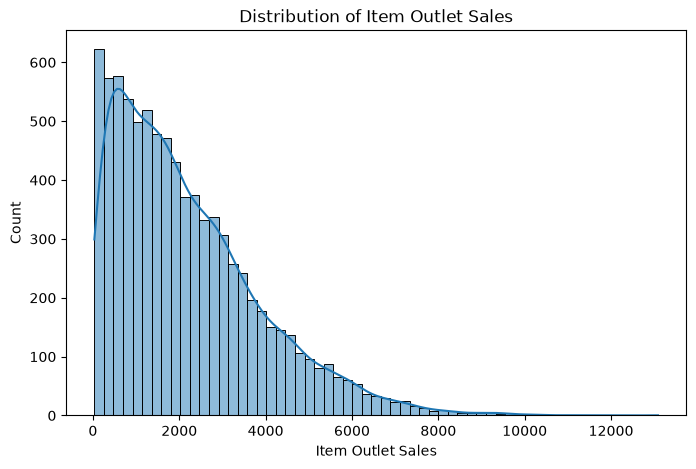

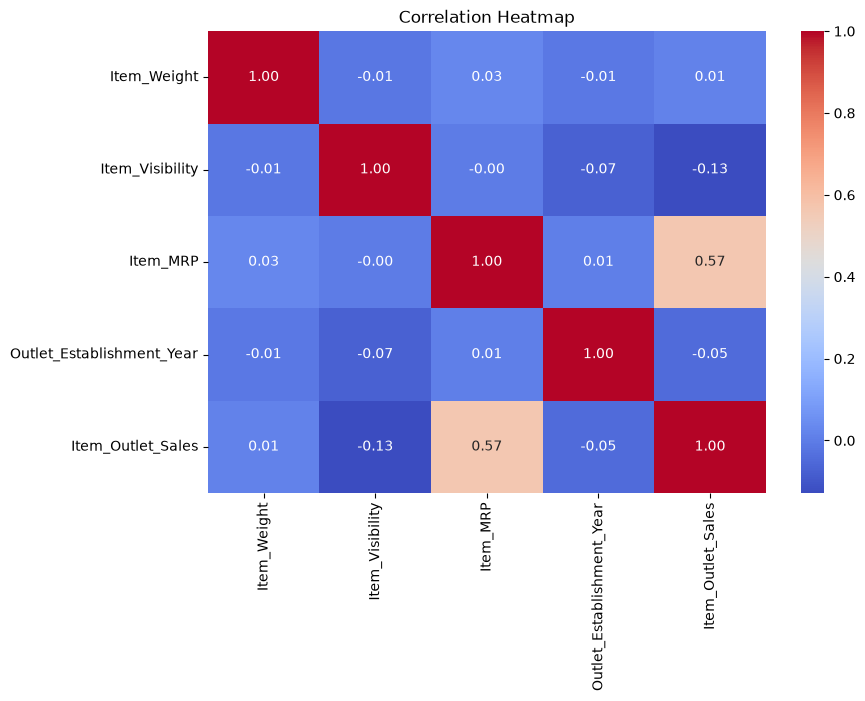

Correlations with Item_Outlet_Sales:


Item_MRP                     0.567574
Item_Weight                  0.014123
Outlet_Establishment_Year   -0.049135
Item_Visibility             -0.128625
Name: Item_Outlet_Sales, dtype: float64

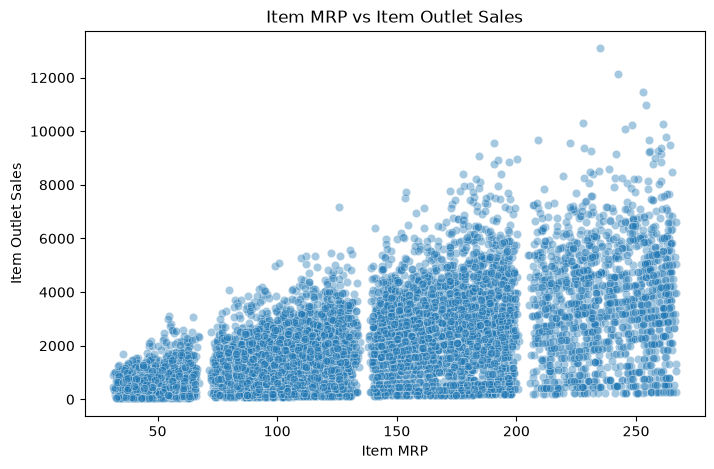

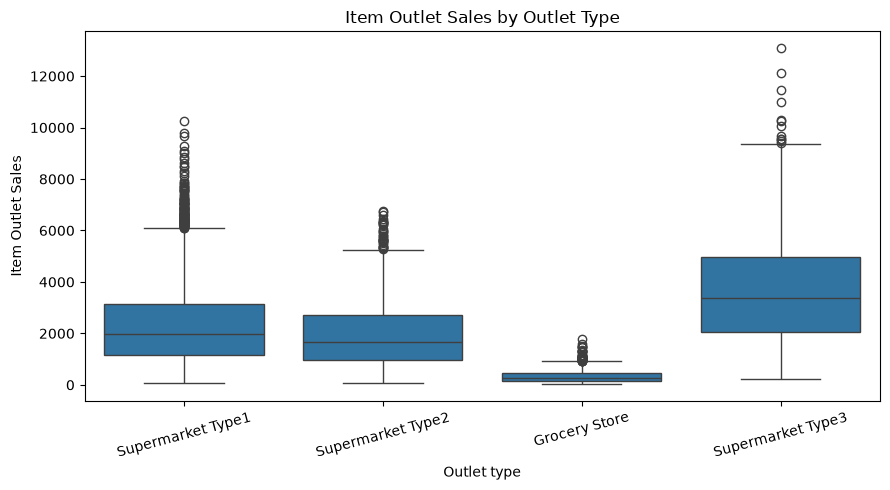

In [70]:

# 1. Histogram: distribution of sales
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Item_Outlet_Sales", kde=True)
plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.show()

# 2. Correlation heatmap: numeric columns
numeric_cols = df.select_dtypes(include="number").columns
correlation = df[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# Print correlations with sales to support your interpretation
print("Correlations with Item_Outlet_Sales:")
display(correlation["Item_Outlet_Sales"].drop("Item_Outlet_Sales").sort_values(ascending=False))

# 3. Scatter plot: item price versus sales
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Item_MRP", y="Item_Outlet_Sales", alpha=0.4)
plt.title("Item MRP vs Item Outlet Sales")
plt.xlabel("Item MRP")
plt.ylabel("Item Outlet Sales")
plt.show()

#4. Boxplot: sales by outlet type
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="Outlet_Type", y="Item_Outlet_Sales", ax=ax)
ax.set(title="Item Outlet Sales by Outlet Type", xlabel="Outlet type", ylabel="Item Outlet Sales")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

**Inferences**: 

The sales statistics in the dataset given show a mean of about 2,181 and a median of about 1,794; the mean being higher suggests sales may be right-skewed, **which the histogram can confirm**. 
Sales also vary substantially, from about 33 to 13,087. 

**The heatmap** shows correlations between numeric features; correlations heatmap shows that Item_MRP has the strongest relationship with Item_Outlet_Sales. In the scatter plot, look for whether sales tend to rise as Item_MRP increases, and note the spread of sales at similar price levels. A correlation or visual pattern indicates association, not necessarily causation. 

With Item_MRP on the x-axis and Item_Outlet_Sales on the y-axis, **the scatter plot suggests a positive relationship**: items with higher MRP generally tend to have higher outlet sales. However, sales vary considerably among items with similar MRP, so price alone does not explain sales; item type, outlet size, outlet location, and other factors may also matter. **This shows an association, not proof that a higher MRP causes higher sales.**

**The Box Plot shows** Supermarket Type 3 has the highest median Item_Outlet_Sales and the widest spread, indicating higher typical sales per item but substantial variation. Supermarket Types 1 and 2 have moderate sales, with Type 1’s median slightly higher in this plot. Grocery Stores have the lowest median sales and a narrower central range, though they also have some high-sales outliers. Overall, sales per item differ by outlet type; these are individual item-sales records, not total outlet revenue.

# 2. Data Preprocessing and Feature Engineering – [2 Marks]

**Perform necessary preprocessing steps such as:**

Handling missing values.  
Encoding categorical variables.  
Feature scaling (if required).   
Explain the preprocessing techniques used.    

In [71]:
# Clean inconsistent fat-content categories
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

target = "Item_Outlet_Sales"

# Item identifiers are labels rather than useful predictive measurements, so these features can be removed
X = df.drop(columns=[target, "Item_Identifier", "Outlet_Identifier"])
y = df[target]

numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(include="object").columns

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
print(f"Numeric features ({len(num_features)}): {num_features}")
print(f"Categorical features ({len(cat_features)}): {cat_features}")

# Numeric preprocessing to handle missing values and scale the data
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing to handle missing values and encode the data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
# Combine numeric and categorical pipelines into a ColumnTransformer
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Split the test and training data before applying preprocessing to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train_processed = preprocessor.fit_transform(X_train)

#Transform applies the same preprocessing to test data without learning from it. That keeps the test set 
#independent and prevents data leakage, so it remains a fair evaluation of how the model handles unseen data.

X_test_processed = preprocessor.transform(X_test)

processed_feature_names = preprocessor.get_feature_names_out()
X_train_processed_df = pd.DataFrame(
X_train_processed,
columns=processed_feature_names,
index=X_train.index
)
X_test_processed_df = pd.DataFrame(
X_test_processed,
columns=processed_feature_names,
index=X_test.index
)
print("Preprocessed training dataset:")
display(X_train_processed_df.describe().T.round(2))
print("Preprocessed test dataset:")
display(X_test_processed_df.describe().T.round(2))

print("Original training shape:", X_train.shape)
print("Preprocessed training shape:", X_train_processed.shape)
print("Preprocessed test shape:", X_test.shape)

print("\nMissing values in preprocessed training data:")
print(X_train_processed_df.isna().sum().sum())

Numeric features (4): ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year']
Categorical features (5): ['Item_Fat_Content', 'Item_Type', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']
Preprocessed training dataset:


,count,mean,std,min,25%,50%,75%,max
numeric__Item_Weight,6818.0,0.00,1.00,-1.96,-0.81,-0.06,0.77,2.01
numeric__Item_Visibility,6818.0,-0.00,1.00,-1.29,-0.76,-0.23,0.56,5.10
numeric__Item_MRP,6818.0,-0.00,1.00,-1.77,-0.76,0.04,0.72,2.00
numeric__Outlet_Establishment_Year,6818.0,0.00,1.00,-1.53,-1.29,0.14,0.73,1.33
categorical__Item_Fat_Content_Low Fat,6818.0,0.64,0.48,0.00,0.00,1.00,1.00,1.00
categorical__Item_Fat_Content_Regular,6818.0,0.36,0.48,0.00,0.00,0.00,1.00,1.00
categorical__Item_Type_Baking Goods,6818.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00
categorical__Item_Type_Breads,6818.0,0.03,0.16,0.00,0.00,0.00,0.00,1.00
categorical__Item_Type_Breakfast,6818.0,0.01,0.11,0.00,0.00,0.00,0.00,1.00
categorical__Item_Type_Canned,6818.0,0.08,0.26,0.00,0.00,0.00,0.00,1.00


Preprocessed test dataset:


,count,mean,std,min,25%,50%,75%,max
numeric__Item_Weight,1705.0,-0.03,1.00,-1.95,-0.86,-0.06,0.75,2.01
numeric__Item_Visibility,1705.0,0.00,1.02,-1.29,-0.76,-0.25,0.54,4.76
numeric__Item_MRP,1705.0,-0.07,0.98,-1.75,-0.79,-0.19,0.62,1.99
numeric__Outlet_Establishment_Year,1705.0,-0.01,0.99,-1.53,-1.29,0.14,0.73,1.33
categorical__Item_Fat_Content_Low Fat,1705.0,0.66,0.47,0.00,0.00,1.00,1.00,1.00
categorical__Item_Fat_Content_Regular,1705.0,0.34,0.47,0.00,0.00,0.00,1.00,1.00
categorical__Item_Type_Baking Goods,1705.0,0.08,0.27,0.00,0.00,0.00,0.00,1.00
categorical__Item_Type_Breads,1705.0,0.04,0.19,0.00,0.00,0.00,0.00,1.00
categorical__Item_Type_Breakfast,1705.0,0.01,0.12,0.00,0.00,0.00,0.00,1.00
categorical__Item_Type_Canned,1705.0,0.08,0.27,0.00,0.00,0.00,0.00,1.00


Original training shape: (6818, 9)
Preprocessed training shape: (6818, 32)
Preprocessed test shape: (1705, 9)

Missing values in preprocessed training data:
0


**Explanation:**

**Techniques used :**

Missing values: Item_Weight is numeric, so missing values are replaced with the median. Outlet_Size is categorical, so missing values are replaced with the most frequent category.

Categorical consistency: LF, low fat, and Low Fat are combined into one category. The same is done for reg and Regular.

Categorical encoding: OneHotEncoder converts categories into separate binary columns. handle_unknown="ignore" prevents errors if the test data contains a category not seen during training.

Scaling: StandardScaler gives numeric features approximately mean 0 and standard deviation 1. 

Train/test separation: Imputers, encoders, and scalers are fitted only on X_train.

**Dropped identifiers: Item_Identifier and Outlet_Identifier contain labels rather than meaningful numeric relationships, so they are excluded.**

# 3. Machine Learning Model Building – [2 Marks]

**Build a Linear Regression model.**

Explain:

Features selected.   
Target variable.   
Regularization method used (if any).   
Reason for selecting Linear Regression.   

In [72]:
# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train_processed, y_train)

# Make predictions
y_train_pred = model.predict(X_train_processed)
y_test_pred = model.predict(X_test_processed)

# Evaluate the model
train_mae = mean_absolute_error(y_train, y_train_pred).__round__(2)
test_mae = mean_absolute_error(y_test, y_test_pred).__round__(2)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred)).__round__(2)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred)).__round__(2)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
print("Training MAE :", train_mae)
print("Test MAE     :", test_mae)
print("Training RMSE:", train_rmse)
print("Test RMSE    :", test_rmse)
print("Training R2  :", train_r2)
print("Test R2      :", test_r2)

print(f"Mean test sales: {y_test_pred.mean():.2f}")
print(f"MAE as % of mean test sales: {100 * test_mae / y_test_pred.mean():.1f}%")

# View model coefficients
processed_feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": processed_feature_names,
    "Coefficient": model.coef_.round(2)
}).sort_values(by="Coefficient", key=abs, ascending=False)

print("\nTop model coefficients:")
display(coefficients.head(15))

print("\nIntercept:", model.intercept_)

Training MAE : 847.29
Test MAE     : 791.6
Training RMSE: 1142.08
Test RMSE    : 1068.94
Training R2  : 0.5590495134315875
Test R2      : 0.5795972247952179
Mean test sales: 2106.99
MAE as % of mean test sales: 37.6%

Top model coefficients:


,Feature,Coefficient
31,categorical__Outlet_Type_Supermarket Type3,2141.59
28,categorical__Outlet_Type_Grocery Store,-1646.75
2,numeric__Item_MRP,979.58
22,categorical__Outlet_Size_High,534.21
30,categorical__Outlet_Type_Supermarket Type2,-370.27
23,categorical__Outlet_Size_Medium,-295.60
3,numeric__Outlet_Establishment_Year,276.19
24,categorical__Outlet_Size_Small,-238.61
18,categorical__Item_Type_Seafood,218.35
27,categorical__Outlet_Location_Type_Tier 3,-210.52



Intercept: 2526.9364907212007


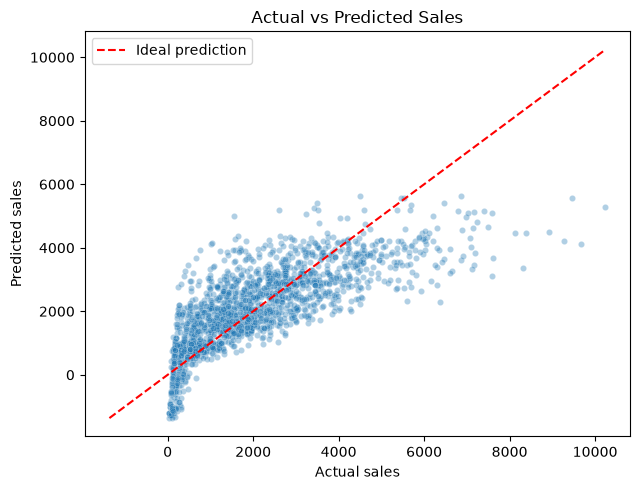

In [73]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(x=y_test, y=y_test_pred, alpha=.35, s=20, ax=ax)
low, high = min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())
ax.plot([low, high], [low, high], linestyle="--", color="red", label="Ideal prediction")
ax.set(title="Actual vs Predicted Sales", xlabel="Actual sales", ylabel="Predicted sales")
ax.legend()
plt.tight_layout()
plt.show()

**Explanation:**

**Features selected**.    

The features are:
* Item_Weight
* Item_Fat_Content
* Item_Visibility
* Item_Type
* Item_MRP
* Outlet_Establishment_Year
* Outlet_Size
* Outlet_Location_Type
* Outlet_Type

**Item_Identifier and Outlet_Identifier are excluded because they are identifiers rather than meaningful predictive measurements.**

**Target variable.  
The target variable is:  Item_Outlet_Sales**

**It is continuous, so the task is a supervised regression problem.**.  

Regularization
Standard LinearRegression uses no regularization. It minimizes the ordinary least-squares error. If overfitting or multicollinearity occurs, alternatives such as Ridge Regression (L2 regularization) or Lasso Regression (L1 regularization) can be used.

**Reason for selecting Linear Regression**.  

Linear Regression is appropriate because:
* The target variable is continuous.
* It establishes a baseline for sales prediction.
* It is fast and easy to interpret.
* It can quantify how changes in features relate to predicted sales.
* StandardScaler was already applied, allowing the coefficients to be compared more meaningfully.
* One-hot encoding has converted categorical variables into numeric form.   

Linear Regression is an interpretable baseline for a continuous outcome. MAE and RMSE are in sales units (lower is better); R² measures the proportion of target variance explained (closer to 1 is better).

# 5. Observations and conclusion

The EDA shows a right-skewed sales target and a positive relationship between MRP and sales. Outlet and product characteristics provide additional signal, and missingness is concentrated in item weight and outlet size. The pipeline handles these gaps with train-fitted imputers and encodes categorical predictors while scaling numeric predictors.

Conclusion: The Linear Regression model explains about 58% of the variation in Item_Outlet_Sales on the test data. Its predictions are off by about 792 sales units on average (MAE); the higher RMSE suggests some predictions have larger errors. Since the mean test sales are about 2,107, the MAE is roughly 37.6% of that mean, so predictions have noticeable error. The model is a useful baseline, but its accuracy is moderate and could be improved by testing other models or capturing nonlinear relationships in future.

